# 02 · Preparación de la matriz de participación
Se agregan los conteos por entidad, distrito de referencia, sexo y grupo de edad para construir
las seis tasas electorales y los cuatro indicadores del modelo. Las correspondencias distritales
son aproximadas y las trayectorias describen segmentos agregados, no a las mismas personas.

In [1]:
print('[02] Leyendo la base limpia.', flush=True)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import utils as U

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format
ANIOS = [2009, 2012, 2015, 2018, 2021, 2024]
COLS_TASA = [f"tasa_{a}" for a in ANIOS]
VARIABLES_CLUSTERING = U.FEATURES_SETS["participacion"]
VARIABLES_DIAGNOSTICO = ["tendencia_general", "exceso_medio"]
VARIABLES_LONGITUDINALES = U.VARIABLES_ACTUALES + U.CURVATURAS + U.VARIABLES_RELATIVAS + U.CURVATURAS_REL
UNIDADES_VARIABLES = U.UNIDADES_INDICADORES
ETIQUETAS_VARIABLES = U.ETIQUETAS_INDICADORES
VERSION_PREPROCESADO = "ccpc_edad114_especificados"
VERSION_VARIABLES = U.VERSION_VARIABLES
GRUPOS_EDAD_VALIDOS = [f"{a}-{a+2}" for a in range(18, 63, 3)] + [
    "63-66", "67-70", "71-74", "75-79", "80+"]
FUENTE = (U.DIR_PROC / "FUENTE.txt").read_text(encoding="utf-8").strip()
if FUENTE != "REAL":
    raise ValueError("Este flujo requiere los CSV reales procesados en el notebook 01.")
ruta_base = U.DIR_PROC / "ccpc_limpio.csv.gz"
if not ruta_base.exists():
    raise FileNotFoundError("Primero completa el notebook 01. Una base .en_proceso.csv.gz no está lista para usarse.")
NIVEL_TERRITORIAL = "distrito"
RUTA_EQUIVALENCIAS = U.DIR_RAW / "equivalencias_territoriales.csv"
# Revisar la ruta antes de leer la base completa.
if not RUTA_EQUIVALENCIAS.exists():
    raise FileNotFoundError(
        f"Falta {RUTA_EQUIVALENCIAS}. Se requiere la tabla de correspondencias de secciones "
        "de cada elección hacia un mismo marco distrital (DEF usa 2021 hasta 2021 y 2023 en 2024). "
        "Columnas: anio, clave_entidad, clave_municipio, seccion, distrito_ref, marco_referencia, tipo_enlace."
    )
conteos = ["lista_nominal", "participantes", "no_participantes", "no_especificados"]
columnas_base = ["anio", "entidad", "sexo", "grupo_edad"] + conteos
columnas_base += ["clave_entidad", "clave_municipio", "seccion"]
columnas_lectura = columnas_base + ["definicion_tasa", "version_preprocesado"]
claves_lectura = [c for c in columnas_base if c not in conteos]
partes = []
filas_leidas = 0
for n_bloque, bloque in enumerate(pd.read_csv(ruta_base, usecols=columnas_lectura, chunksize=100_000, low_memory=False), start=1):
    filas_leidas += len(bloque)
    if n_bloque == 1 or n_bloque % 10 == 0:
        print(f"[02] Lectura: {n_bloque} bloques, {filas_leidas:,} filas", flush=True)
    if not bloque["version_preprocesado"].isin({VERSION_PREPROCESADO}).all():
        raise ValueError("La base limpia no coincide con la preparación de edades del notebook 01. Vuelve a ejecutarlo.")
    if not bloque["definicion_tasa"].eq("especificados").all():
        raise ValueError("La base debe usar SV/(LN−NS).")
    # Los cortes exactos ya se aplicaron sobre EDAD en el 01. No reagrupar intervalos.
    if not bloque["grupo_edad"].isin(GRUPOS_EDAD_VALIDOS).all():
        raise ValueError("Grupos de edad incompatibles. Ejecuta 01 con el nuevo límite de 114 años.")
    partes.append(bloque.groupby(claves_lectura, observed=True, dropna=False, as_index=False)[conteos].sum(min_count=1))
print(f"[02] Lectura finalizada: {n_bloque} bloques, {filas_leidas:,} filas. Agregando...", flush=True)
df = pd.concat(partes, ignore_index=True).groupby(
    claves_lectura, observed=True, dropna=False, as_index=False)[conteos].sum(min_count=1)
partes.clear()
del bloque, partes
import gc
gc.collect()
df["version_preprocesado"] = VERSION_PREPROCESADO
df["definicion_tasa"] = "especificados"
print(f"{len(df):,} filas agregadas | años: {sorted(df.anio.unique())}")


[02] Leyendo la base limpia.
[02] Lectura: 1 bloques, 100,000 filas
[02] Lectura: 10 bloques, 1,000,000 filas
[02] Lectura: 20 bloques, 2,000,000 filas
[02] Lectura: 30 bloques, 3,000,000 filas
[02] Lectura: 40 bloques, 4,000,000 filas
[02] Lectura: 50 bloques, 5,000,000 filas
[02] Lectura: 60 bloques, 6,000,000 filas
[02] Lectura: 70 bloques, 7,000,000 filas
[02] Lectura: 80 bloques, 8,000,000 filas
[02] Lectura: 90 bloques, 9,000,000 filas
[02] Lectura: 100 bloques, 10,000,000 filas
[02] Lectura: 110 bloques, 11,000,000 filas
[02] Lectura: 120 bloques, 12,000,000 filas
[02] Lectura: 130 bloques, 13,000,000 filas
[02] Lectura: 140 bloques, 14,000,000 filas
[02] Lectura: 150 bloques, 15,000,000 filas
[02] Lectura: 160 bloques, 16,000,000 filas
[02] Lectura finalizada: 162 bloques, 16,184,204 filas. Agregando...
16,184,204 filas agregadas | años: [np.int64(2009), np.int64(2012), np.int64(2015), np.int64(2018), np.int64(2021), np.int64(2024)]


## 2.1. Correspondencia territorial
La tabla de equivalencias asigna las secciones de cada elección al marco distrital de referencia.
Se admiten enlaces exactos y aproximados; los registros sin destino se reportan por entidad.

In [2]:
MIN_DENOMINADOR_POR_ANIO = 30

base = df
del df
base["anio"] = pd.to_numeric(base["anio"], errors="coerce").astype("Int64")
for c in ["clave_entidad", "clave_municipio", "seccion"]:
    base[c] = pd.to_numeric(base[c], errors="coerce").astype("Int64")
base["territorio_comparable"] = base["clave_entidad"].between(1, 32).fillna(False)
eq = pd.read_csv(RUTA_EQUIVALENCIAS, dtype={"distrito_ref": "string"})
llave = ["anio", "clave_entidad", "clave_municipio", "seccion"]
cols_eq = llave + ["distrito_ref", "marco_referencia", "tipo_enlace"]
faltan_eq = set(cols_eq) - set(eq.columns)
if faltan_eq:
    raise ValueError(f"Faltan columnas de equivalencia: {sorted(faltan_eq)}")
for c in llave:
    eq[c] = pd.to_numeric(eq[c], errors="coerce").astype("Int64")
if eq[llave].isna().any().any():
    raise ValueError("La tabla de equivalencias contiene claves de origen vacías.")
eq["tipo_enlace"] = eq["tipo_enlace"].astype("string").str.strip().str.lower()
eq["distrito_ref"] = eq["distrito_ref"].str.strip().replace("", pd.NA)
enlaces_admitidos = eq["tipo_enlace"].isin(["exacto", "aproximado"])
if eq.loc[enlaces_admitidos, "marco_referencia"].dropna().nunique() != 1 or eq.loc[enlaces_admitidos, "marco_referencia"].isna().any():
    raise ValueError("Los enlaces admitidos deben referirse a un único marco no vacío.")
base = base.merge(eq[cols_eq], on=llave, how="left", validate="many_to_one")
base["territorio_comparable"] &= base["tipo_enlace"].isin(["exacto", "aproximado"]) & base["distrito_ref"].notna()

print("Filas sin enlace territorial elegible:", int((~base.territorio_comparable).sum()))
perdidas_territoriales = base.loc[~base.territorio_comparable].groupby("entidad").agg(
    filas_sin_enlace=("anio", "size"), ln_sin_enlace=("lista_nominal", "sum"))
totales_territoriales = base.groupby("entidad").agg(
    filas_base=("anio", "size"), ln_base=("lista_nominal", "sum"))
perdidas_territoriales = totales_territoriales.join(perdidas_territoriales).fillna(0)
perdidas_territoriales["porcentaje_filas_sin_enlace"] = 100 * perdidas_territoriales.filas_sin_enlace / perdidas_territoriales.filas_base
perdidas_territoriales["porcentaje_ln_sin_enlace"] = 100 * perdidas_territoriales.ln_sin_enlace / perdidas_territoriales.ln_base.replace(0, np.nan)
print("Registros sin correspondencia territorial por entidad:")
print("LN acumulada de las seis elecciones; no representa personas únicas. Filas ya agregadas en 01.")
display(perdidas_territoriales.sort_values("porcentaje_ln_sin_enlace", ascending=False).round(2))
base = base.loc[base.territorio_comparable & base.anio.isin(ANIOS)].copy()
if base.empty:
    raise ValueError("No quedan observaciones con enlace territorial elegible. Revisar configuración y cobertura.")
claves = ["entidad", "distrito_ref", "sexo", "grupo_edad"]
conteos = ["lista_nominal", "participantes", "no_participantes", "no_especificados"]


Filas sin enlace territorial elegible: 2249
Pérdidas de la base limpia por estado: menor porcentaje significa mayor cobertura.
LN acumulada de las seis elecciones; no representa personas únicas. Filas ya agregadas en 01.


,filas_base,ln_base,filas_sin_enlace,ln_sin_enlace,porcentaje_filas_sin_enlace,porcentaje_ln_sin_enlace
entidad,,,,,,
BAJA CALIFORNIA,447961,15869158,640,"211,049.000",0.140,1.330
QUERETARO,204683,9018265,160,"47,319.000",0.080,0.520
YUCATAN,266307,9028267,160,"39,139.000",0.060,0.430
CHIHUAHUA,735132,16137134,200,"68,843.000",0.030,0.430
GUANAJUATO,746906,25331110,320,"93,775.000",0.040,0.370
JALISCO,851345,34412466,320,"101,580.000",0.040,0.300
PUEBLA,639223,26006953,240,"74,794.000",0.040,0.290
MEXICO,1542683,68384329,145,"32,507.000",0.010,0.050
SINALOA,891576,12376703,64,196.000,0.010,0.000


## 2.2. Tasas por segmento y elección
Se suman SV, NV, NS y LN antes de calcular SV/(LN−NS). Los registros no especificados se
conservan en los conteos, pero quedan fuera del denominador. Las tasas ausentes no se rellenan.
Cada segmento requiere las seis elecciones y al menos 30 registros especificados en cada una.

El denominador medio resume el soporte de la trayectoria. Su raíz cuadrada se utiliza como peso
en el notebook 03: un soporte cien veces mayor recibe diez veces el peso.

In [3]:
print('[02] Construyendo segmentos y pivotes de las seis elecciones.', flush=True)
g = base.groupby(claves + ["anio"], observed=True, as_index=False)[conteos].sum(min_count=1)
g["denominador"] = g["lista_nominal"] - g["no_especificados"]
g["tasa"] = g["participantes"] / g["denominador"].where(g["denominador"] > 0)
pivotes = {}
for numero_indicador, nombre in enumerate(conteos + ["denominador", "tasa"], start=1):
    print(f"[02] Pivote {numero_indicador}/{len(conteos)+2}: {nombre}", flush=True)
    pivote = g.pivot(index=claves, columns="anio", values=nombre).reindex(columns=ANIOS)
    pivote.columns = [f"{nombre}_{a}" for a in ANIOS]
    pivotes[nombre] = pivote
unidades_todas = pd.concat(pivotes.values(), axis=1).reset_index()
cols_ln = [f"lista_nominal_{a}" for a in ANIOS]
cols_denom = [f"denominador_{a}" for a in ANIOS]
unidades_todas["n_elecciones_validas"] = unidades_todas[COLS_TASA].notna().sum(axis=1)
unidades_todas["cobertura_completa"] = unidades_todas["n_elecciones_validas"].eq(6)
unidades_todas["ln_media"] = unidades_todas[cols_ln].mean(axis=1)
# Soporte observado de la trayectoria completa; NS no aporta peso al modelo.
unidades_todas["denominador_medio"] = unidades_todas[cols_denom].mean(axis=1, skipna=False)
unidades_todas["lista_nominal_minima"] = unidades_todas[cols_ln].min(axis=1)
for a in ANIOS:
    unidades_todas[f"proporcion_no_especificada_{a}"] = (
        unidades_todas[f"no_especificados_{a}"] / unidades_todas[f"lista_nominal_{a}"].where(unidades_todas[f"lista_nominal_{a}"] > 0))
unidades_todas["denominador_minimo"] = unidades_todas[cols_denom].min(axis=1)
unidades_todas["soporte_suficiente"] = unidades_todas[cols_denom].ge(MIN_DENOMINADOR_POR_ANIO).all(axis=1)
unidades_todas["elegible_clustering"] = unidades_todas.cobertura_completa & unidades_todas.soporte_suficiente
unidades_todas["motivo_exclusion"] = np.select([
    ~unidades_todas.cobertura_completa, ~unidades_todas.soporte_suficiente,
], ["Cobertura incompleta", "Denominador insuficiente en alguna elección"], default="Conservado")
unidades_todas["n_tasas_imputadas"] = 0
unidades_todas["nivel_territorial"] = NIVEL_TERRITORIAL
unidades_todas["comparabilidad_territorial"] = "Correspondencias aproximadas al marco DERFE 2023"
unidades_todas["marco_referencia"] = base["marco_referencia"].dropna().iloc[0] if len(base) else "Sin referencia"
unidades_todas["definicion_tasa"] = "especificados"
unidades_todas["version_preprocesado"] = VERSION_PREPROCESADO
unidades_todas["version_variables"] = VERSION_VARIABLES
# Identificadores del segmento distrital.
unidades_todas["distrito"] = unidades_todas["distrito_ref"]
unidades_todas["id_distrito"] = unidades_todas[["entidad", "distrito_ref"]].astype(str).agg(" | ".join, axis=1)
unidades_todas["tipo_seccion"] = "Agregado de todos los tipos"
unidades_todas["id_segmento"] = unidades_todas[claves].astype(str).agg(" | ".join, axis=1)

unidades_todas["variables_clustering"] = ";".join(VARIABLES_CLUSTERING)
unidades_todas["variables_diagnostico"] = ";".join(VARIABLES_DIAGNOSTICO)
# Liberar agregados intermedios que ya no se necesitan.
del base, pivote, pivotes
gc.collect()


[02] Construyendo segmentos y pivotes de las seis elecciones.
[02] Pivote 1/6: lista_nominal
[02] Pivote 2/6: participantes
[02] Pivote 3/6: no_participantes
[02] Pivote 4/6: no_especificados
[02] Pivote 5/6: denominador
[02] Pivote 6/6: tasa


0

## 2.3. Cobertura y exclusiones
Se muestran los segmentos excluidos y su proporción por entidad y sexo. Los porcentajes de LN media
se calculan sobre los segmentos disponibles. Las categorías presentes en una sola elección no
cumplen la cobertura histórica requerida, aunque sus registros sean válidos.

In [4]:
cobertura = unidades_todas.n_elecciones_validas.value_counts().reindex(range(7), fill_value=0).sort_index()
display(cobertura.rename("segmentos").to_frame())
resumen_estados = unidades_todas.assign(
    excluido=~unidades_todas.elegible_clustering,
    ln_media_excluida=unidades_todas.ln_media.where(~unidades_todas.elegible_clustering, 0),
).groupby("entidad").agg(
    segmentos_iniciales=("id_segmento", "size"), segmentos_excluidos=("excluido", "sum"),
    ln_media_inicial=("ln_media", "sum"), ln_media_excluida=("ln_media_excluida", "sum"))
resumen_estados["porcentaje_segmentos_excluidos"] = 100 * resumen_estados.segmentos_excluidos / resumen_estados.segmentos_iniciales
resumen_estados["porcentaje_ln_media_excluida"] = 100 * resumen_estados.ln_media_excluida / resumen_estados.ln_media_inicial.where(resumen_estados.ln_media_inicial > 0)
display(resumen_estados.sort_values("porcentaje_segmentos_excluidos", ascending=False))
display(unidades_todas.motivo_exclusion.value_counts().rename("segmentos").to_frame())
# Identificar qué poblaciones quedan fuera, además del reporte por estado.
exclusiones_sexo = unidades_todas.assign(excluido=~unidades_todas.elegible_clustering).groupby("sexo").agg(
    segmentos_iniciales=("id_segmento", "size"), segmentos_excluidos=("excluido", "sum"))
exclusiones_sexo["porcentaje_excluido"] = 100 * exclusiones_sexo.segmentos_excluidos / exclusiones_sexo.segmentos_iniciales
display(exclusiones_sexo)


,segmentos
n_elecciones_validas,
0,3
1,95
2,0
3,0
4,0
5,0
6,12000


,segmentos_iniciales,segmentos_excluidos,ln_media_inicial,ln_media_excluida,porcentaje_segmentos_excluidos,porcentaje_ln_media_excluida
entidad,,,,,,
CIUDAD DE MEXICO,909,29,"7,519,221.333",32.000,3.190,0.000
JALISCO,823,23,"5,718,501.833",25.000,2.795,0.000
AGUASCALIENTES,123,3,"913,440.000",3.000,2.439,0.000
CHIHUAHUA,367,7,"2,678,054.333",7.000,1.907,0.000
NAYARIT,122,2,"815,031.833",3.000,1.639,0.000
NUEVO LEON,568,8,"3,753,823.333",9.000,1.408,0.000
BAJA CALIFORNIA,364,4,"2,609,688.167",4.000,1.099,0.000
QUERETARO,242,2,"1,495,159.333",2.000,0.826,0.000
TLAXCALA,121,1,"895,473.833",1.000,0.826,0.000


,segmentos
motivo_exclusion,
Conservado,12000
Cobertura incompleta,98


,segmentos_iniciales,segmentos_excluidos,porcentaje_excluido
sexo,,,
Hombres,6000,0,0.000
Mujeres,6000,0,0.000
No Binario,98,98,100.000


## 2.4. Indicadores de participación
1. **Participación media:** promedio de las seis tasas, en porcentaje.
2. **Brecha presidencial–intermedia:** diferencia entre promedios por tipo de elección, en puntos porcentuales.
3. **Cambio reciente:** [(p2021 − p2015) + (p2024 − p2018)] / 12, en puntos porcentuales por año.
4. **Irregularidad de trayectoria:** raíz del promedio de residuos cuadrados al ajustar un nivel,
   un efecto presidencial y una tendencia lineal común a las seis tasas, en puntos porcentuales.

Las tendencias, curvaturas y referencias nacionales por edad y sexo se conservan para el análisis descriptivo.

In [5]:
# Referencia nacional por edad, sexo y año, calculada con segmentos elegibles.
print("[02] Calculando benchmark por grupo de edad, sexo y año (1/2).", flush=True)
benchmark_edad = U.agregar_benchmark_edad(unidades_todas, g, claves, ANIOS)
print("[02] Benchmark terminado; calculando características longitudinales (2/2).", flush=True)
for variable, valores in U.indicadores_trayectoria(unidades_todas[COLS_TASA]).items():
    unidades_todas[variable] = valores
p = unidades_todas[COLS_TASA] * 100.0
p.columns = ANIOS
completa = unidades_todas.cobertura_completa
unidades_todas["participacion_media"] = p.mean(axis=1, skipna=False)
unidades_todas["brecha_presidencial_intermedia"] = (
    p[[2012, 2018, 2024]].mean(axis=1, skipna=False) - p[[2009, 2015, 2021]].mean(axis=1, skipna=False))
unidades_todas["tendencia_intermedia"] = (p[2021] - p[2009]) / 12.0
unidades_todas["tendencia_presidencial"] = (p[2024] - p[2012]) / 12.0
# Resumen de las pendientes presidencial e intermedia.
unidades_todas["tendencia_general"] = (unidades_todas["tendencia_presidencial"] + unidades_todas["tendencia_intermedia"]) / 2.0
unidades_todas["diferencia_tendencias"] = unidades_todas["tendencia_presidencial"] - unidades_todas["tendencia_intermedia"]
unidades_todas["curvatura_intermedia"] = p[2021] - 2.0 * p[2015] + p[2009]
unidades_todas["curvatura_presidencial"] = p[2024] - 2.0 * p[2018] + p[2012]
unidades_todas.loc[~completa, VARIABLES_LONGITUDINALES + ["tendencia_intermedia", "tendencia_presidencial"]] = np.nan

unidades_todas["edad_inferior"] = unidades_todas.grupo_edad.map(U.edad_inferior)
unidades_todas["ciclo_vida"] = unidades_todas.edad_inferior.map(U.ciclo_vida)
region_ref = dict(U.REGION_POR_ENTIDAD)
region_ref.update({"QUERETARO": "Circ. 5", "HIDALGO": "Circ. 4"})
unidades_todas["region"] = unidades_todas.entidad.map(region_ref).fillna("Sin región")
unidades_todas["marco_circunscripcion"] = "2023 (referencia fija)"
unidades = unidades_todas.loc[unidades_todas.elegible_clustering].copy().reset_index(drop=True)
if not unidades.empty:
    assert np.isfinite(unidades[VARIABLES_LONGITUDINALES].to_numpy()).all()
    assert unidades[COLS_TASA].ge(0).all().all() and unidades[COLS_TASA].le(1).all().all()
print(f"Segmentos listos para clustering: {len(unidades):,} de {len(unidades_todas):,}")
display(unidades[["entidad", "sexo", "grupo_edad"] + VARIABLES_LONGITUDINALES].head(20))



[02] Calculando benchmark por grupo de edad, sexo y año (1/2).
[02] Benchmark terminado; calculando características longitudinales (2/2).
Segmentos listos para clustering: 12,000 de 12,098


,entidad,sexo,grupo_edad,participacion_media,brecha_presidencial_intermedia,tendencia_general,diferencia_tendencias,curvatura_intermedia,curvatura_presidencial,exceso_medio,brecha_relativa,tendencia_relativa,diferencia_tendencias_relativa,pendiente_ols_relativa,curvatura_intermedia_rel,curvatura_presidencial_rel
0,AGUASCALIENTES,Hombres,18-20,44.314,12.662,0.539,-1.212,25.613,6.604,-2.820,-0.665,0.510,-0.105,0.447,19.664,10.503
1,AGUASCALIENTES,Hombres,21-23,35.875,11.387,0.553,-1.211,20.216,1.645,-3.874,-2.069,0.549,-0.171,0.443,16.439,6.146
2,AGUASCALIENTES,Hombres,24-26,33.755,11.507,0.550,-1.143,18.620,-1.441,-4.268,-2.092,0.560,-0.183,0.452,15.176,4.957
3,AGUASCALIENTES,Hombres,27-29,33.528,11.114,0.513,-1.025,22.836,-2.102,-4.369,-2.574,0.558,-0.166,0.436,18.308,6.058
4,AGUASCALIENTES,Hombres,30-32,36.175,12.120,0.748,-1.020,18.625,-4.638,-4.295,-1.576,0.644,-0.378,0.543,16.161,6.567
5,AGUASCALIENTES,Hombres,33-35,39.435,12.852,0.539,-1.157,14.492,-2.661,-4.257,-1.033,0.534,-0.298,0.458,14.001,6.463
6,AGUASCALIENTES,Hombres,36-38,43.274,13.110,0.265,-1.415,15.346,-2.151,-3.467,-0.694,0.347,-0.438,0.298,15.753,4.605
7,AGUASCALIENTES,Hombres,39-41,46.285,13.240,0.310,-1.326,18.960,3.053,-3.373,-0.158,0.413,-0.316,0.373,19.246,8.183
8,AGUASCALIENTES,Hombres,42-44,49.223,12.389,0.311,-1.272,22.009,3.872,-3.160,-0.499,0.382,-0.293,0.335,21.680,8.693
9,AGUASCALIENTES,Hombres,45-47,51.472,12.799,0.382,-1.052,19.288,1.687,-3.388,0.032,0.408,-0.106,0.374,17.398,5.449


## 2.5. Distribución de las variables
Resumen de las tasas, los indicadores y la composición de la matriz preparada.

,count,mean,std,min,25%,50%,75%,max
participacion_media,"12,000.000",56.951,11.817,22.729,48.119,58.070,66.304,87.564
brecha_presidencial_intermedia,"12,000.000",12.699,5.895,-3.863,8.752,12.716,16.588,31.541
cambio_reciente,"12,000.000",0.173,0.895,-2.607,-0.469,0.167,0.812,3.385
irregularidad_trayectoria,"12,000.000",3.320,1.865,0.062,1.953,2.847,4.361,12.295
tendencia_general,"12,000.000",0.199,0.615,-2.027,-0.225,0.177,0.619,2.571
diferencia_tendencias,"12,000.000",-0.803,0.765,-3.762,-1.260,-0.671,-0.219,1.688
curvatura_intermedia,"12,000.000",1.051,13.626,-52.812,-7.542,2.719,10.473,44.292
curvatura_presidencial,"12,000.000",-1.669,8.189,-33.413,-7.192,-1.522,3.775,38.622
exceso_medio,"12,000.000",0.076,6.698,-23.258,-4.057,0.029,4.227,27.980
brecha_relativa,"12,000.000",-0.294,5.757,-18.289,-4.037,-0.128,3.753,16.769


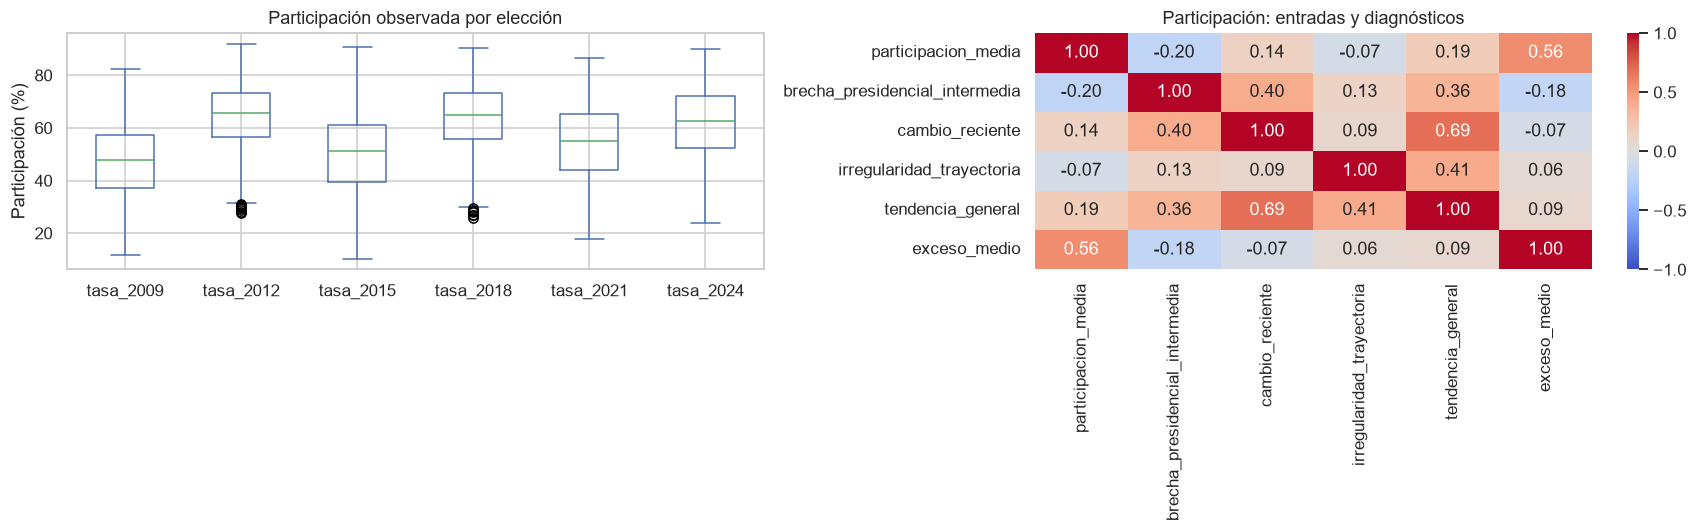

,segmentos
region,
Circ. 1,2440
Circ. 4,2440
Circ. 3,2400
Circ. 2,2360
Circ. 5,2360


,segmentos
ciclo_vida,
Adultos (30-50),4200
Mediana edad (51-66),3000
Jóvenes (18-29),2400
Mayores (67+),2400


,segmentos
sexo,
Hombres,6000
Mujeres,6000


In [6]:
if unidades.empty:
    print("No hay segmentos elegibles. Revisar cobertura, equivalencias y soporte antes de ejecutar 03.")
else:
    display(unidades[list(dict.fromkeys(VARIABLES_CLUSTERING + VARIABLES_LONGITUDINALES)) + ["ln_media", "denominador_minimo"]].describe().T)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    (unidades[COLS_TASA] * 100).plot(kind="box", ax=axes[0])
    axes[0].set(title="Participación observada por elección", ylabel="Participación (%)")
    sns.heatmap(unidades[VARIABLES_CLUSTERING + VARIABLES_DIAGNOSTICO].corr(), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=axes[1])
    axes[1].set_title("Participación: entradas y diagnósticos")
    plt.tight_layout(); plt.show()
    for c in ["region", "ciclo_vida", "sexo"]:
        display(unidades[c].value_counts(dropna=False).rename("segmentos").to_frame())


## 2.6. Guardar la matriz
`unidades.csv` contiene los segmentos elegibles. `unidades_diagnostico.csv` conserva también
las exclusiones y sus motivos. La referencia nacional por edad y sexo se guarda por separado.

In [7]:
unidades_todas.to_csv(U.DIR_PROC / "unidades_diagnostico.csv", index=False)
if unidades.empty:
    raise ValueError("No se actualizó unidades.csv: no hay trayectorias elegibles. No continuar al 03.")
unidades.to_csv(U.DIR_PROC / "unidades.csv", index=False)
print("Guardado:", U.DIR_PROC / "unidades.csv", unidades.shape)
print("Diagnóstico:", U.DIR_PROC / "unidades_diagnostico.csv")
print("Variables de entrada del 03:", VARIABLES_CLUSTERING)
benchmark_edad.to_csv(U.DIR_TAB / "benchmark_nacional_edad.csv", index=False)


Guardado: C:\Users\pokem\OneDrive\Documentos\UNAM\SEMESTRE 3\HACKATON_INE\Datocracia\Datocracia\data\processed\unidades.csv (12000, 95)
Diagnóstico: C:\Users\pokem\OneDrive\Documentos\UNAM\SEMESTRE 3\HACKATON_INE\Datocracia\Datocracia\data\processed\unidades_diagnostico.csv
Variables de entrada del 03: ['participacion_media', 'brecha_presidencial_intermedia', 'cambio_reciente', 'irregularidad_trayectoria']
